# U.S. Road Accident Analysis 

**A portfolio level data analysis project**

In [1]:
### Importing neccessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. DATA LOADING AND OVERVIEW

- Converted the CSV dataset into Parquet file, so dataset reading and other executions can be faster.

In [2]:
df=pd.read_parquet("US_Accidents_March23.parquet")
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


In [3]:
print(f"The shape of this dataset is: {df.shape}")

The shape of this dataset is: (7728394, 46)


In [4]:
print(f"Name of the columns:\n{df.columns}")

Name of the columns:
Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='object')


In [5]:
print(f"Number of duplicate rows:{df.duplicated().sum()}")

Number of duplicate rows:0


In [6]:
# Columns to drop, keeping only the meaningful columns

drop_columns = ['Source','End_Lat','End_Lng','Description','Street','Country','Timezone','Airport_Code','Weather_Timestamp',
                'Wind_Chill(F)','No_Exit','Station','Turning_Loop','Civil_Twilight','Nautical_Twilight','Astronomical_Twilight']

df.drop(columns=drop_columns, inplace=True)

print(f"After dropping the columns:{df.columns}")
print("Number of columns:", len(df.columns))

After dropping the columns:Index(['ID', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng',
       'Distance(mi)', 'City', 'County', 'State', 'Zipcode', 'Temperature(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'Railway', 'Roundabout',
       'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Sunrise_Sunset'],
      dtype='object')
Number of columns: 30


In [7]:
print(f"Shape after dropping columns: {df.shape}")

Shape after dropping columns: (7728394, 30)


In [8]:
print("=== Info of the remaining columns ===\n")
df.info()

=== Info of the remaining columns ===



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 30 columns):
 #   Column             Dtype  
---  ------             -----  
 0   ID                 object 
 1   Severity           int64  
 2   Start_Time         object 
 3   End_Time           object 
 4   Start_Lat          float64
 5   Start_Lng          float64
 6   Distance(mi)       float64
 7   City               object 
 8   County             object 
 9   State              object 
 10  Zipcode            object 
 11  Temperature(F)     float64
 12  Humidity(%)        float64
 13  Pressure(in)       float64
 14  Visibility(mi)     float64
 15  Wind_Direction     object 
 16  Wind_Speed(mph)    float64
 17  Precipitation(in)  float64
 18  Weather_Condition  object 
 19  Amenity            bool   
 20  Bump               bool   
 21  Crossing           bool   
 22  Give_Way           bool   
 23  Junction           bool   
 24  Railway            bool   
 25  Roundabout        

In [9]:
df.head()

,ID,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),City,County,State,...,Bump,Crossing,Give_Way,Junction,Railway,Roundabout,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset
0,A-1,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,0.01,Dayton,Montgomery,OH,...,False,False,False,False,False,False,False,False,False,Night
1,A-2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,0.01,Reynoldsburg,Franklin,OH,...,False,False,False,False,False,False,False,False,False,Night
2,A-3,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,0.01,Williamsburg,Clermont,OH,...,False,False,False,False,False,False,False,False,True,Night
3,A-4,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,0.01,Dayton,Montgomery,OH,...,False,False,False,False,False,False,False,False,False,Night
4,A-5,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,0.01,Dayton,Montgomery,OH,...,False,False,False,False,False,False,False,False,True,Day


In [10]:
df.isna().sum()

ID                         0
Severity                   0
Start_Time                 0
End_Time                   0
Start_Lat                  0
Start_Lng                  0
Distance(mi)               0
City                     253
County                     0
State                      0
Zipcode                 1915
Temperature(F)        163853
Humidity(%)           174144
Pressure(in)          140679
Visibility(mi)        177098
Wind_Direction        175206
Wind_Speed(mph)       571233
Precipitation(in)    2203586
Weather_Condition     173459
Amenity                    0
Bump                       0
Crossing                   0
Give_Way                   0
Junction                   0
Railway                    0
Roundabout                 0
Stop                       0
Traffic_Calming            0
Traffic_Signal             0
Sunrise_Sunset         23246
dtype: int64

## 2. DATA CLEANING & PREPROCESSING

- **To avoid introducing artificial values into the dataset. I decided not to fill missing values (NaN) in numerical columns**. For example, the Precipitation(in) column contains a substantial number of missing values. **Replacing these missing values with the mean precipitation could create a misleading distribution and affect subsequent analyses involving precipitation and accident severity**.

In [11]:
### Filling text columns

text_columns=["City","Zipcode","Wind_Direction","Weather_Condition","Sunrise_Sunset"]

for col in text_columns:
    df[col]=df[col].fillna("Unknown")

In [12]:
df["Severity"].value_counts()

Severity
2    6156981
3    1299337
4     204710
1      67366
Name: count, dtype: int64

## 2.1 Feature Engineering

- The dataset's documentation **defines Severity in terms of the impact of an accident on traffic flow**, Level 1 means the least traffic impact and Level 4 means a significant impact, such as a longer traffic delay. **It does not define these levels as degrees of bodily injury or crash fatality.**

In [13]:
### Creating text values for severity code values

severity_map = {
    1: "Level 1 - Lowest Traffic Impact",
    2: "Level 2",
    3: "Level 3",
    4: "Level 4 - Highest Traffic Impact"
}

df["Severity_Label"] = df["Severity"].map(severity_map)

In [14]:
state_map = {
    "CA": "California",
    "FL": "Florida",
    "TX": "Texas",
    "SC": "South Carolina",
    "NY": "New York",
    "NC": "North Carolina",
    "VA": "Virginia",
    "PA": "Pennsylvania",
    "MN": "Minnesota",
    "OR": "Oregon",
    "AZ": "Arizona",
    "GA": "Georgia",
    "IL": "Illinois",
    "TN": "Tennessee",
    "MI": "Michigan",
    "LA": "Louisiana",
    "NJ": "New Jersey",
    "MD": "Maryland",
    "OH": "Ohio",
    "WA": "Washington",
    "AL": "Alabama",
    "UT": "Utah",
    "CO": "Colorado",
    "OK": "Oklahoma",
    "MO": "Missouri",
    "CT": "Connecticut",
    "IN": "Indiana",
    "MA": "Massachusetts",
    "WI": "Wisconsin",
    "KY": "Kentucky",
    "NE": "Nebraska",
    "MT": "Montana",
    "IA": "Iowa",
    "AR": "Arkansas",
    "NV": "Nevada",
    "KS": "Kansas",
    "DC": "District of Columbia",
    "RI": "Rhode Island",
    "MS": "Mississippi",
    "DE": "Delaware",
    "WV": "West Virginia",
    "ID": "Idaho",
    "NM": "New Mexico",
    "NH": "New Hampshire",
    "WY": "Wyoming",
    "ND": "North Dakota",
    "ME": "Maine",
    "VT": "Vermont",
    "SD": "South Dakota"
}

df["State"] = df["State"].map(state_map)

In [15]:
# Converting to datetime
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed")
df["End_Time"] = pd.to_datetime(df["End_Time"], format="mixed")

# Extract date/time features
df["Year"] = df["Start_Time"].dt.year
df["Month"] = df["Start_Time"].dt.month_name()
df["Day"] = df["Start_Time"].dt.day
df["Hour"] = df["Start_Time"].dt.hour
df["Day_of_Week"] = df["Start_Time"].dt.day_name()

# Is the accident occured on Weekend / Weekday
df["Weekend_Weekday"] = df["Start_Time"].dt.dayofweek.apply(lambda x: "Weekend" if x >= 5 else "Weekday")

In [16]:
# Calculate accident duration
df["Duration_Minutes"] = (df["End_Time"]-df["Start_Time"]).dt.total_seconds()/60

In [17]:
# Converting Farhenhite to Celsius
df["Temperature(F)"] = ((df["Temperature(F)"] - 32) * 5/9)
df.rename(columns={"Temperature(F)": "Temperature(C)"}, inplace=True)


In [18]:
# Creating Humidity Group

print(f"Minimum Humidity: {df['Humidity(%)'].min()}")
print(f"Maximum Humidity: {df['Humidity(%)'].max()}")

df["Humidity_Group"] = pd.cut(df["Humidity(%)"],bins=[0, 20, 40, 60, 80, 100],labels=["Very Low", 
                                "Low", "Moderate", "High", "Very High"],include_lowest=True)

Minimum Humidity: 1.0
Maximum Humidity: 100.0


In [19]:
# Creating Visibility Group

print(f"Minimum Visibility: {df['Visibility(mi)'].min()}")
print(f"Maximum Visibility: {df['Visibility(mi)'].max()}")

df["Visibility_Group"] = pd.cut(df["Visibility(mi)"],bins=[-0.01, 1, 3, 5, 10, 140],
                                labels=["Very Poor", "Poor", "Moderate", "Good", "Very Good"],include_lowest=True)

Minimum Visibility: 0.0
Maximum Visibility: 140.0


In [20]:
# Creating Wind Speed Group

print(f"Minimum Wind Speed: {df['Wind_Speed(mph)'].min()}")
print(f"Maximum Wind Speed: {df['Wind_Speed(mph)'].max()}")

df["Wind_Speed_Group"] = pd.cut(df["Wind_Speed(mph)"],bins=[-0.01, 5, 15, 25, 50,  float("inf")],
                                labels=["Calm","Light","Moderate","Strong","Extreme"],include_lowest=True)

Minimum Wind Speed: 0.0
Maximum Wind Speed: 1087.0


In [21]:
# Creating Precipitation Group

print(f"Minimum Precipitation: {df['Precipitation(in)'].min()}")
print(f"Maximum Precipitation: {df['Precipitation(in)'].max()}")

df["Precipitation_Group"] = pd.cut(df["Precipitation(in)"],bins=[-0.01, 0, 0.1, 0.5, 2, 6, 36.47],
                                   labels=["No Rain","Very Light","Light","Moderate","Heavy","Severe"],include_lowest=True)

Minimum Precipitation: 0.0
Maximum Precipitation: 36.47


In [22]:
df_wind = df[df["Wind_Speed(mph)"] > 200][["Severity", "State", "Day","Month", "Year", "Wind_Speed(mph)"]]
df_wind

,Severity,State,Day,Month,Year,Wind_Speed(mph)
64265,2,California,20,January,2017,241.7
114580,3,California,13,June,2016,822.8
114588,3,California,13,June,2016,822.8
114633,3,California,13,June,2016,822.8
114640,2,California,13,June,2016,822.8
114647,3,California,13,June,2016,822.8
887089,2,California,16,September,2021,243.0
1696997,2,Texas,10,December,2019,230.0
1697006,2,Texas,10,December,2019,230.0
1697009,2,Texas,10,December,2019,230.0


## 3. Overall Accident Overview

In [23]:
# How many accidents occured?
total_acc=df["ID"].__len__()
print(f"Total {total_acc} accidents occured.")

# Accidents by Severity Level
severity=df["Severity"].value_counts()
sever_rate=((severity/total_acc) * 100).round(1)
print(f"\nSeverity rates:\n{sever_rate}")

# Accidents recorded states
states=df["State"].unique()
print(f"\nTotal {states.__len__()} states accident records are available.\n")

# Accident recorded cities
cities=df["City"].unique()
print(f"Total {cities.__len__()} cities accident records are available.")

# Accident recorded counties
counties=df["County"].unique()
print(f"\nTotal {counties.__len__()} counties accident records are available.")

# Average Accident duration
avg_duration=df["Duration_Minutes"].mean()
print(f"\nAverage Duration of Accidents is {avg_duration} minutes.")

# Average Distance Affected
avg_distance=df["Distance(mi)"].mean()
print(f"Average Distance of Accidents is {avg_distance} mi.")

#weekend_weekday
weekend_day=df["Weekend_Weekday"].value_counts()
weekend_day_rate=((weekend_day/total_acc)*100).round(1)
weekend_day_rate

Total 7728394 accidents occured.

Severity rates:
Severity
2    79.7
3    16.8
4     2.6
1     0.9
Name: count, dtype: float64

Total 49 states accident records are available.

Total 13679 cities accident records are available.

Total 1871 counties accident records are available.

Average Duration of Accidents is 444.4209573522665 minutes.
Average Distance of Accidents is 0.5618422831523753 mi.


Weekend_Weekday
Weekday    84.1
Weekend    15.9
Name: count, dtype: float64

#### Number of Accidents Per Year

Number of accidents per Year:
Year
2022    1762452
2021    1563753
2020    1178913
2019     954303
2018     893426
2017     718093
2016     410821
2023     246633
Name: count, dtype: int64


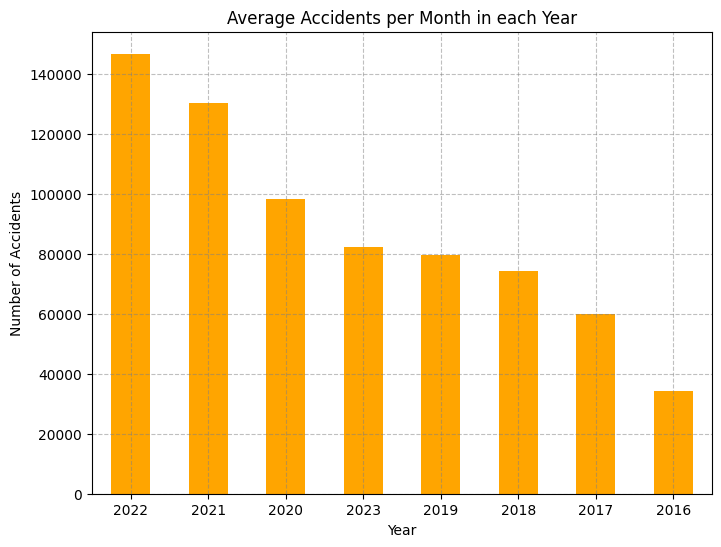

In [24]:
acc_per_year=df["Year"].value_counts()
print(f"Number of accidents per Year:\n{acc_per_year}")

# Average accidents per month in each year 
monthly_rate = acc_per_year / 12
monthly_rate.loc[2023] = acc_per_year.loc[2023] / 3
monthly_rate=monthly_rate.sort_values(ascending=False)
monthly_rate.plot(kind="bar",color="orange",figsize=(8,6))
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=0)
plt.grid(alpha=0.5,linestyle="--",color="grey")
plt.title("Average Accidents per Month in each Year")
plt.show()

### Insight

* From **2016 to 2022**, the number of recorded traffic accidents shows a consistent increasing trend.
* Although **2023 has the lowest total number of recorded accidents**, this is because the dataset contains records for **January to March only**.
* To make a fair comparison, the **average number of accidents per month** was calculated for each year.
* The analysis shows that **2023 already recorded more than 80,000 accidents per month** during its first quarter.
* Based on this monthly rate, 2023 could potentially become the **4th highest year in terms of total recorded accidents** if the trend continued throughout the year.
* Therefore, the lower total for 2023 should **not be interpreted as a decrease in accidents**. Instead, the available data suggests that the increasing accident trend continued into the first quarter of 2023.


In [25]:
first_half=df[df["Day"]<=15]
last_half=df[df["Day"]>15]

print(
      f"Accidents in the first half of months: {first_half.__len__()}." 
      f"\nAccidents in the last  half of months: {last_half.__len__()}."
      )

Accidents in the first half of months: 3791822.
Accidents in the last  half of months: 3936572.


In [26]:
df["Hour"].value_counts(ascending=False)

Hour
7     587472
16    581969
8     577576
17    576015
15    525855
14    448846
18    432042
6     405837
13    396445
9     363034
11    355040
12    355001
10    342706
19    295121
5     228182
20    225226
21    191452
22    167645
4     159852
23    126539
0     112378
1      97071
2      93227
3      83863
Name: count, dtype: int64

In [27]:
df["Day_of_Week"].value_counts(ascending=False)

Day_of_Week
Friday       1366499
Thursday     1316229
Wednesday    1312389
Tuesday      1290929
Monday       1210921
Saturday      668683
Sunday        562744
Name: count, dtype: int64

In [28]:
weekend_weekday=df["Weekend_Weekday"].value_counts(ascending=False)
weekend_weekday

Weekend_Weekday
Weekday    6496967
Weekend    1231427
Name: count, dtype: int64

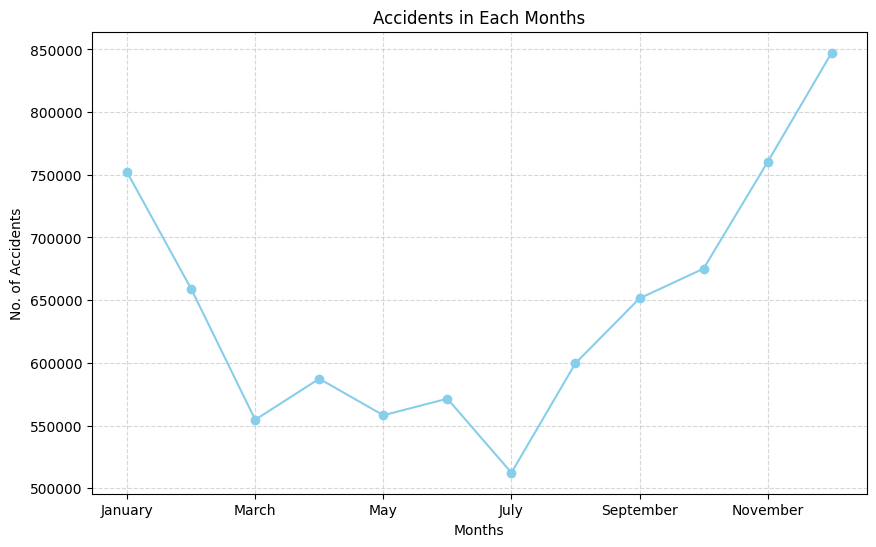

In [29]:
monthly_accidents=df["Month"].value_counts(ascending=True)

month_order = ["January", "February", "March", "April","May", "June", "July", "August","September", "October", "November", "December"]
monthly_accidents = monthly_accidents.reindex(month_order)
monthly_accidents.plot(kind="line",color="skyblue",marker="o",figsize=(10,6))
plt.title("Accidents in Each Months")
plt.xlabel("Months")
plt.ylabel("No. of Accidents")
plt.grid(alpha=0.5,linestyle="--")
plt.show()

In [30]:
severity_by_month=df.groupby(["Month","Severity"]).size().unstack()
severity_by_month

Severity,1,2,3,4
Month,,,,
April,10860,455453,104509,16478
August,9715,453588,120957,15406
December,105,718622,107801,20815
February,391,540220,101895,16478
January,114,627020,105637,19175
July,8120,386495,102766,14954
June,14759,422511,116330,17773
March,4686,432299,101530,16080
May,15584,420480,105386,16726


In [31]:
severity_by_weekend_day=df.groupby(["Weekend_Weekday","Severity"]).size().unstack()

severity_rate = (severity_by_weekend_day.div(severity_by_weekend_day.sum(axis=1), axis=0) * 100)

severity_rate


Severity,1,2,3,4
Weekend_Weekday,,,,
Weekday,0.966235,79.978581,16.601962,2.453222
Weekend,0.372738,78.023220,17.923352,3.680689


In [32]:
duration_by_weekend_day=df.groupby("Weekend_Weekday")["Duration_Minutes"].mean()
duration_by_weekend_day


Weekend_Weekday
Weekday    410.237407
Weekend    624.772207
Name: Duration_Minutes, dtype: float64

In [33]:
distance_by_weekend_day=df.groupby("Weekend_Weekday")["Distance(mi)"].mean()
distance_by_weekend_day


Weekend_Weekday
Weekday    0.544581
Weekend    0.652914
Name: Distance(mi), dtype: float64

### Insights
* The dataset contains **7.73 million recorded accidents across 49 states, 13,679 cities, and 1,871 counties**.
* Severity Level 2 dominates, **accounting for 79.7% of all records**, followed by Level 3 (16.8%), Level 4 (2.6%), and Level 1 (0.9%).
* The **average traffic-impact duration is approximately 444 minutes (7.4 hours)**, while the **average recorded accident distance is 0.56 miles**.
* **84.1% of accidents occurred on weekdays**, compared with 15.9% on weekends.
* Accident frequency varies considerably throughout the day. **Peak accidents were recorded at 6-9 am, 1-6 pm**, these each timezones are top 10 timezones of accidents. 
* Most accidents were recorded **at 7am (587472), 4pm (581969), 8am (577576)**. Most lowest accidents were recorded **at midnight 0-3am**. Overall, the distribution shows **two noticeable periods of higher accident frequency: the morning period and the afternoon/evening period**.
* **Wednesday-Friday are the peak days for recorded accidents**, with each of these days having **more than 1.3M+ accidents were recorded**. Most accidents recorded on Friday (1366499), followed by Thursday and Wednesday (1316229 & 1312389). Lowest accidents **were recorded on Saturday and Sunday**, which are the weekend days. 
* **November, December & January** is the top 3 most recorded accidents months, where **December ranked first, followed by November & January**. Acccidents during Summer (June-August) & Spring (March-May) were comparatively lower than in other seasons, while **650K+ accidents in Autumn (September-November) and Winter (December-February) were recorded.**
* **Weekend accidents show a slightly higher proportion of serious and most-severe accidents (17.92% and 3.68%)** compared with weekdays (16.60% and 2.45%), while **moderate accidents account for the majority on both days.**
* **Accidents recorded on weekends have a substantially longer average duration (624 minutes / 10.24 hours)** compared with weekdays (410 minutes / 6.83 hours). The **average affected distance is also slightly higher on weekends (0.65 mi)** than on weekdays (0.54 mi).

*Note: Severity represents traffic-flow impact, not injury severity. Weekday and weekend percentages are based on total records, not daily accident rates.*

## 4. Geographical Analysis

### 4.1 State Wise Analysis

In [34]:
top_states=df["State"].value_counts(ascending=False).head(10)
print(f"\nTop 10 highest accidents recorded state:\n{top_states}")


Top 10 highest accidents recorded state:
State
California        1741433
Florida            880192
Texas              582837
South Carolina     382557
New York           347960
North Carolina     338199
Virginia           303301
Pennsylvania       296620
Minnesota          192084
Oregon             179660
Name: count, dtype: int64


In [35]:
severity_top_states=df[df["State"].isin(top_states.index)].groupby(["State","Severity"]).size().unstack()
severity_top_states_rate=(severity_top_states.div(severity_top_states.sum(axis=1),axis=0)*100).round(2)
severity_top_states_rate.sort_values(by=4, ascending=False)

Severity,1,2,3,4
State,,,,
Virginia,1.03,76.05,16.92,6.00
Pennsylvania,0.58,83.61,10.46,5.35
Oregon,0.74,90.57,5.42,3.28
New York,0.36,76.42,20.14,3.09
North Carolina,1.52,86.65,8.75,3.08
Florida,0.80,85.88,11.82,1.49
Texas,0.73,77.37,20.66,1.24
South Carolina,1.61,86.48,11.10,0.81
California,0.59,83.03,15.61,0.78


In [36]:
weekend_weekday_top_states = df[df["State"].isin(top_states.index)].groupby(["State","Weekend_Weekday"]).size().unstack()
weekend_weekday_top_states_rate = (weekend_weekday_top_states.div(weekend_weekday_top_states.sum(axis=1),axis=0)*100).round(2)
weekend_weekday_top_states_rate.sort_values(by="Weekend",ascending=False)

Weekend_Weekday,Weekday,Weekend
State,,
Oregon,77.12,22.88
California,79.47,20.53
Virginia,82.20,17.80
Minnesota,82.40,17.60
New York,82.75,17.25
Pennsylvania,83.01,16.99
Florida,85.74,14.26
Texas,87.01,12.99
South Carolina,87.26,12.74


In [37]:
top_states_bump = df[df["State"].isin(top_states.index)].groupby(["State","Bump"]).size().unstack()
top_states_bump_rate = (top_states_bump.div(top_states_bump.sum(axis=1),axis=0)*100).round(2)
top_states_bump_rate.sort_values(by=False,ascending=False)

Bump,False,True
State,,
South Carolina,100.00,0.00
Minnesota,100.00,NaN
Pennsylvania,99.99,0.01
Virginia,99.99,0.01
Florida,99.97,0.03
Texas,99.96,0.04
North Carolina,99.95,0.05
New York,99.95,0.05
California,99.94,0.06


In [38]:
top_states_avg_duration=df[df["State"].isin(top_states.index)].groupby("State")["Duration_Minutes"].mean().round(2)
top_states_avg_duration.sort_values(ascending=False)

State
Oregon            912.80
New York          214.10
Pennsylvania      189.82
North Carolina    149.06
Florida           144.67
Virginia          132.37
Minnesota         123.27
California        120.08
South Carolina    110.00
Texas             105.54
Name: Duration_Minutes, dtype: float64

In [39]:
top_states_humidity=df[df["State"].isin(top_states.index)].groupby(["State","Humidity_Group"],observed=False).size().unstack()
top_states_humidity_rate = (top_states_humidity.div(top_states_humidity.sum(axis=1),axis=0)*100).round(2)
top_states_humidity_rate.sort_values(by="Very High",ascending=False)

Humidity_Group,Very Low,Low,Moderate,High,Very High
State,,,,,
Oregon,2.50,11.10,17.65,27.78,40.97
South Carolina,0.87,13.73,23.33,23.03,39.05
Minnesota,0.21,7.19,19.37,36.08,37.15
Virginia,0.69,13.50,26.50,23.83,35.49
Florida,0.11,4.04,24.02,36.61,35.22
Pennsylvania,0.34,9.66,27.10,28.05,34.86
North Carolina,0.73,15.28,26.57,23.73,33.69
Texas,2.41,15.64,25.23,26.87,29.85
New York,0.56,12.02,28.51,29.16,29.75


In [40]:
top_states_humidity_severity=df[df["State"].isin(top_states.index)].groupby(["Humidity_Group","Severity"],observed=False).size().unstack()
top_states_humidity_severity_rate = (top_states_humidity_severity.div(top_states_humidity_severity.sum(axis=1),axis=0)*100).round(2)
top_states_humidity_severity_rate

Severity,1,2,3,4
Humidity_Group,,,,
Very Low,0.91,85.50,12.59,1.00
Low,0.70,83.56,14.16,1.57
Moderate,0.64,82.81,14.74,1.81
High,0.72,82.42,15.04,1.82
Very High,0.97,82.77,14.11,2.15


In [41]:
top_states_visibility=df[df["State"].isin(top_states.index)].groupby(["State","Visibility_Group"],observed=False).size().unstack()
top_states_visibility_rate = (top_states_visibility.div(top_states_visibility.sum(axis=1),axis=0)*100).round(2)
top_states_visibility_rate.sort_values(by="Very Poor",ascending=False)

Visibility_Group,Very Poor,Poor,Moderate,Good,Very Good
State,,,,,
Minnesota,8.33,6.85,5.78,79.04,0.00
Oregon,6.00,4.16,3.88,85.96,0.00
Pennsylvania,4.85,5.56,4.66,84.45,0.47
New York,4.63,4.89,2.97,85.75,1.76
South Carolina,2.72,3.38,3.62,90.27,0.00
Virginia,2.65,3.50,3.33,90.52,0.00
North Carolina,2.42,4.05,3.12,90.41,0.00
California,1.86,3.33,4.00,90.71,0.10
Texas,1.81,3.03,3.24,90.22,1.70


In [42]:
top_states_visibility_severity = df[df["State"].isin(top_states.index)].groupby(["Visibility_Group","Severity"],observed=False).size().unstack()
top_states_visibility_severity_rate = (top_states_visibility_severity.div(top_states_visibility_severity.sum(axis=1),axis=0)*100).round(2)
top_states_visibility_severity_rate

Severity,1,2,3,4
Visibility_Group,,,,
Very Poor,0.40,86.71,10.58,2.32
Poor,0.48,80.85,16.77,1.90
Moderate,0.49,82.06,15.71,1.74
Good,0.82,82.88,14.45,1.85
Very Good,0.73,74.58,21.90,2.78


In [43]:
top_states_precipitation=df[df["State"].isin(top_states.index)].groupby(["State","Precipitation_Group"],observed=False).size().unstack()
top_states_precipitation_rate = (top_states_precipitation.div(top_states_precipitation.sum(axis=1),axis=0)*100).round(2)
top_states_precipitation_rate

Precipitation_Group,No Rain,Very Light,Light,Moderate,Heavy,Severe
State,,,,,,
California,93.94,4.88,1.17,0.02,0.00,0.00
Florida,92.23,5.39,1.98,0.39,0.01,0.00
Minnesota,90.90,8.24,0.79,0.07,0.00,0.00
New York,86.42,11.52,1.81,0.09,0.00,0.16
North Carolina,89.50,8.09,2.20,0.21,0.00,0.00
Oregon,84.23,14.43,1.32,0.01,0.00,0.00
Pennsylvania,88.09,10.17,1.64,0.10,0.00,0.00
South Carolina,90.73,7.27,1.78,0.21,0.00,0.00
Texas,91.66,6.27,1.78,0.28,0.01,0.00


In [44]:
top_states_precipitation_severity=df[df["State"].isin(top_states.index)].groupby(["Precipitation_Group","Severity"],observed=False).size().unstack()
top_states_precipitation_severity_rate = (top_states_precipitation_severity.div(top_states_precipitation_severity.sum(axis=1),axis=0)*100).round(2)
top_states_precipitation_severity_rate

Severity,1,2,3,4
Precipitation_Group,,,,
No Rain,1.04,88.59,8.55,1.82
Very Light,0.58,81.42,15.82,2.18
Light,0.71,77.94,19.46,1.89
Moderate,1.05,76.81,20.92,1.21
Heavy,0.92,79.82,19.27,0.00
Severe,0.00,54.78,43.82,1.40


## Top 10 States – Key Findings

1. Accident Volume vs. Severity Distribution

California recorded the highest number of accidents (**1.7M+**), followed by Florida (**800K+**) and Texas (**580K+**). However, these states had relatively low proportions of Level 4 accidents. California recorded just **0.78%**, compared with Florida (**1.49%**) and Texas (**1.24%**). This suggests that higher accident volumes do not necessarily correspond to higher proportions of the most severe accidents.

2. Distribution of Level 2 and Level 3 Accidents

Level 2 accidents dominated across all ten states, with Oregon recording the highest proportion (**90.5%**), followed by North Carolina (**86.65%**) and South Carolina (**86.48%**). In contrast, Texas had the highest proportion of Level 3 accidents (**20.66%**), followed by New York (**20.14%**) and California (**15.61%**). This highlights differences in severity distribution across states.

3. Weekday vs. Weekend Accident Distribution

Most accidents occurred on weekdays across the top ten states. However, Oregon recorded the highest weekend accident proportion (**23%**), followed by California (**20.53%**). This variation may reflect differences in weekend travel patterns, recreational activities, and traffic conditions.

4. Accident Distribution Near Road Bumps

Almost all recorded accidents across the ten states occurred away from road bumps. In California, despite having more than **1.7 million accidents**, only **0.06%** were recorded near bumps. Further investigation using road infrastructure data and bump locations could help determine whether infrastructure distribution plays a role in these patterns.

5. Average Accident Duration

Oregon recorded the highest average accident duration (**912 minutes**), more than **four times** that of second-ranked New York (**214 minutes**). This substantial difference highlights variations in recorded accident durations and warrants further investigation into traffic management and accident clearance procedures.

6. Accident Distribution Across Humidity Levels

A considerable proportion of accidents occurred under High and Very High humidity conditions. Oregon recorded approximately **40%** of its accidents under Very High humidity, while around **50%** of California's accidents occurred under High and Very High humidity conditions. This highlights the prevalence of accidents during humid conditions, although humidity alone cannot establish their cause.

7. Accident Severity Across Humidity Conditions

Level 2 accidents dominated across all humidity categories, accounting for more than **82%** of recorded accidents in each group. However, Level 4 accidents showed an increasing proportion as humidity levels increased, rising from **1.00% under Very Low humidity to 2.15% under Very High humidity**. Similarly, Level 3 accidents increased from **12.59% to 15.04%** between Very Low and High humidity before declining to 14.11% under Very High humidity. This suggests a variation in severity distribution across humidity conditions, with Very High humidity showing the highest proportion of Level 4 accidents. One particularly interesting observation is that the **Level 4 proportion under Very High humidity (2.15%) is more than twice that under Very Low humidity (1.00%)**.

8. Humidity vs. Visibility Conditions

Despite the high proportion of accidents recorded under humid conditions, most incidents occurred under Good visibility. In Oregon, approximately **67%** of accidents occurred under High and Very High humidity, while only **10%** occurred under Poor and Very Poor visibility. Similarly, California recorded around **90%** of accidents under Good visibility, with only approximately **5%** under Poor and Very Poor visibility. This suggests that high humidity does not necessarily coincide with reduced visibility in the recorded accident data.

9. Accident Severity Across Visibility Conditions

Level 2 accidents dominated across all visibility categories, accounting for approximately **75–87%** of recorded incidents. However, Level 3 accidents showed a notable variation, reaching their highest proportion under Very Good visibility (**21.90%**), compared with **10.58%** under Very Poor visibility. Similarly, Level 4 accidents recorded their highest proportion under Very Good visibility (**2.78%**). Very Good visibility recorded **24.68%** combined Level 3 and Level 4 accidents, the highest among all visibility categories. Very Poor visibility recorded only **12.90%** combined Level 3 and Level 4 accidents. **This suggests that reduced visibility does not necessarily correspond to a higher proportion of severe accidents in the recorded data.**

10. Accident Distribution Across Precipitation Levels

Across all ten states, most accidents occurred under No Rain conditions, followed by Very Light precipitation. California recorded the highest counts in both categories, with approximately **1.10 million** and **623.5K** accidents, respectively. In contrast, considerably fewer accidents were recorded under Heavy and Severe precipitation conditions.

11. Accident Severity Across Precipitation Conditions

Level 2 accidents dominated most precipitation categories, accounting for **76–89%** of recorded incidents under No Rain to Heavy precipitation conditions. However, Level 3 accidents showed a clear increase across precipitation categories, rising from **8.55% under No Rain to 43.82% under Severe precipitation**. Under Severe precipitation, Level 3 accidents became the dominant category, while Level 2 accidents dropped to **54.78%**. This suggests a notable shift toward higher accident severity under more severe precipitation conditions. Level 4 accidents did not increase consistently with precipitation. Their proportion reached 2.18% under Very Light precipitation but dropped to 0% under Heavy precipitation.


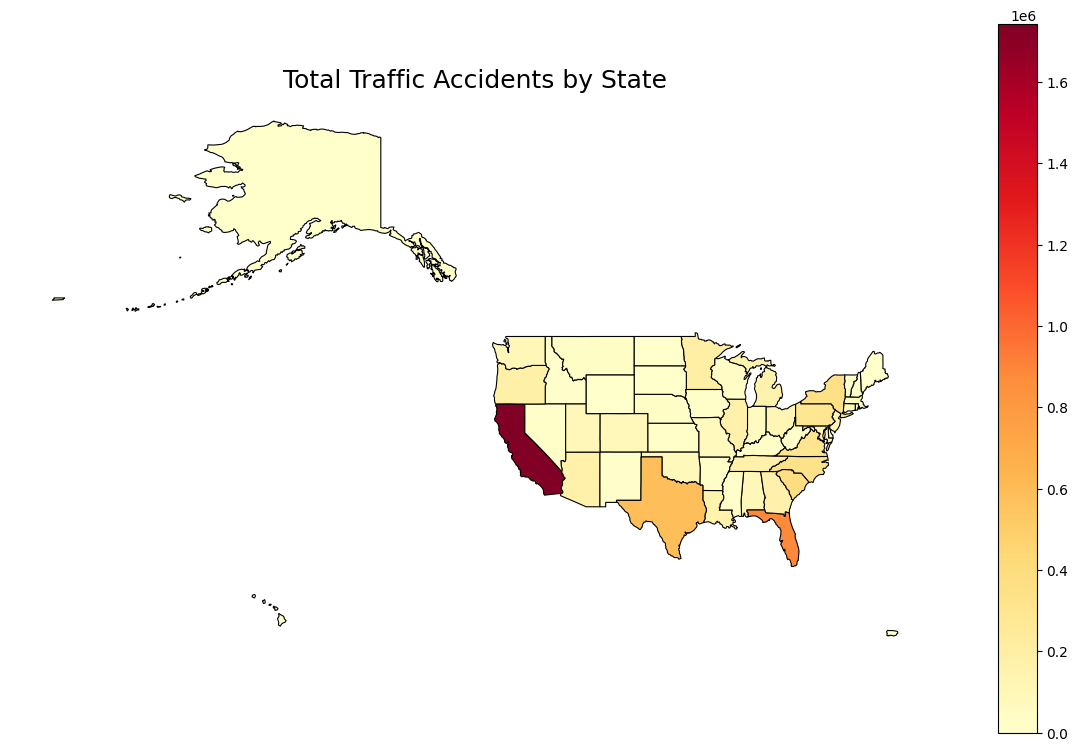

In [45]:
import geopandas as gpd
import pandas as pd


# US states GeoJSON
url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"

states = gpd.read_file(url)

state_accidents = (df["State"].value_counts().rename_axis("name").reset_index(name="Accident_Count"))

states_map = states.merge(state_accidents,on="name",how="left")

states_map["Accident_Count"] = states_map["Accident_Count"].fillna(0)

fig, ax = plt.subplots(figsize=(15, 10))

states_map.plot(column="Accident_Count",cmap="YlOrRd",linewidth=0.8,edgecolor="black",legend=True,ax=ax)

ax.set_title("Total Traffic Accidents by State",fontsize=18)

ax.set_axis_off()

plt.show()



* Geographical Distribution of Traffic Accidents

The state-level map reveals a significant concentration of recorded accidents in **California**, which leads with more than **1.7 million incidents**. Florida and Texas follow, with approximately **880K** and **580K** accidents, respectively. In comparison, most other states show considerably lower accident counts. This highlights the geographical variation in accident distribution across the United States.

Records used: 7728394


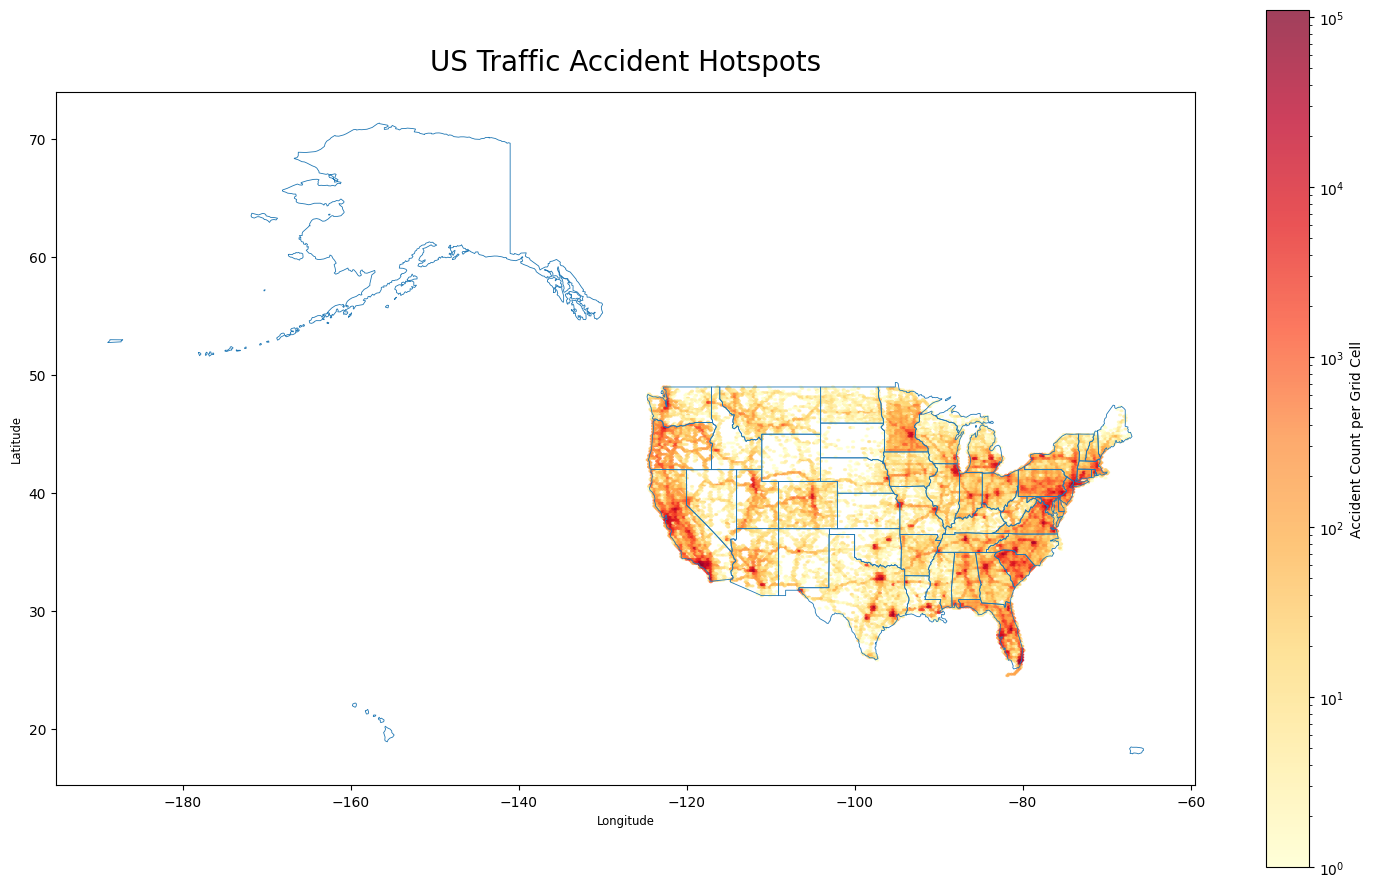

In [46]:

import geopandas as gpd
from matplotlib.colors import LogNorm

# 1. Remove invalid coordinates

hotspot_df = df[df["Start_Lat"].notna() & df["Start_Lng"].notna()].copy()

# Keep valid US coordinates
hotspot_df = hotspot_df[(hotspot_df["Start_Lat"].between(24, 50)) & (hotspot_df["Start_Lng"].between(-125, -66))]

print("Records used:", len(hotspot_df))

# 2. Load US state boundaries

states = gpd.read_file("https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json")

# 3. Create the map

fig, ax = plt.subplots(figsize=(15, 9))

# State boundaries
states.boundary.plot(ax=ax,linewidth=0.6)

# Accident density / hotspots
hb = ax.hexbin(hotspot_df["Start_Lng"],hotspot_df["Start_Lat"],gridsize=180,mincnt=1,bins="log",cmap="YlOrRd",alpha=0.75)

# Colorbar
cbar = fig.colorbar(hb, ax=ax)
cbar.set_label("Accident Count per Grid Cell")

# Title
ax.set_title("US Traffic Accident Hotspots",fontsize=20,pad=15)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

* Geographical Accident Hotspots

The geospatial hotspot map reveals that accidents are not evenly distributed across the United States. Instead, they are concentrated along major road networks and densely populated urban areas. Notable concentrations appear across **California's coastal regions, the Northeast corridor, the Great Lakes region, and parts of the Southeast, particularly Florida**. Several smaller hotspots are also visible across major cities and transportation corridors. These patterns highlight **geographical areas with particularly high concentrations of recorded accidents and provide useful locations for further investigation into traffic safety and road infrastructure**.

### 4.2 City Wise Analysis

In [47]:
len(df["City"].unique())

13679

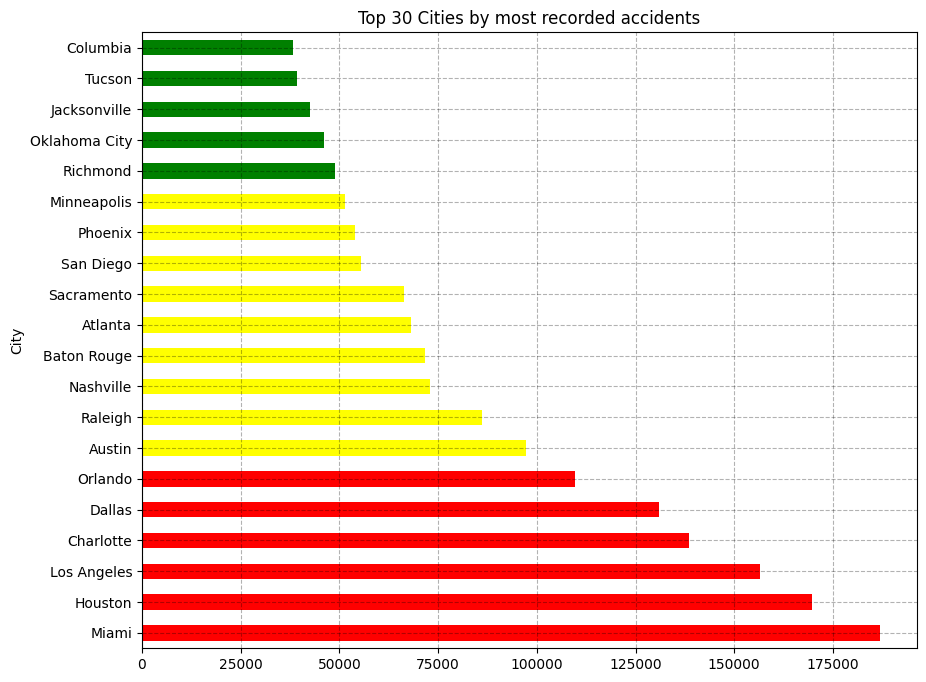

In [ ]:
top_cities = df["City"].value_counts()
top_20 = top_cities.head(20)
colors = []

for count in top_20:
    if count > 100000:
        colors.append("red")
    elif count > 50000:
        colors.append("yellow")
    else:
        colors.append("green")

top_20.plot(kind="barh",color=colors,figsize=(10,8))
plt.title("Top 20 Cities by most recorded accidents")
plt.grid(linestyle="--",alpha=0.3,color="black")
plt.show()

In [49]:
weekend_weekday_top_cities_severity = df[df["City"].isin(top_20.index)].groupby(["Weekend_Weekday","Severity"]).size().unstack()
weekend_weekday_top_cities_severity_rate = (weekend_weekday_top_cities_severity.div(weekend_weekday_top_cities_severity.sum(axis=1),axis=0)*100).round(2)
weekend_weekday_top_cities_severity_rate

Severity,1,2,3,4
Weekend_Weekday,,,,
Weekday,1.16,83.16,14.84,0.83
Weekend,0.60,79.34,18.53,1.53


In [50]:
top_cities_railway = df[df["City"].isin(top_20.index)].groupby(["City","Railway"]).size().unstack()
top_cities_railway_rate = (top_cities_railway.div(top_cities_railway.sum(axis=1),axis=0)*100).round(2)
top_cities_railway_rate

Railway,False,True
City,,
Atlanta,99.30,0.70
Austin,99.70,0.30
Baton Rouge,97.75,2.25
Charlotte,97.29,2.71
Columbia,98.00,2.00
Dallas,98.95,1.05
Houston,98.30,1.70
Jacksonville,99.82,0.18
Los Angeles,97.93,2.07


In [51]:
top_cities_railway_severity = df[df["City"].isin(top_20.index)].groupby(["Railway","Severity"]).size().unstack()
top_cities_railway_severity_rate = (top_cities_railway_severity.div(top_cities_railway_severity.sum(axis=1),axis=0)*100).round(2)
top_cities_railway_severity_rate

Severity,1,2,3,4
Railway,,,,
False,1.08,82.56,15.43,0.93
True,1.74,89.28,8.44,0.55


In [52]:
top_cities_signal = df[df["City"].isin(top_20.index)].groupby(["City","Traffic_Signal"]).size().unstack()
top_cities_signal_rate = (top_cities_signal.div(top_cities_signal.sum(axis=1),axis=0)*100).round(2)
top_cities_signal_rate

Traffic_Signal,False,True
City,,
Atlanta,91.06,8.94
Austin,68.83,31.17
Baton Rouge,76.59,23.41
Charlotte,64.50,35.50
Columbia,87.50,12.50
Dallas,74.68,25.32
Houston,69.05,30.95
Jacksonville,89.90,10.10
Los Angeles,87.26,12.74


In [53]:
top_cities_signal_severity = df[df["City"].isin(top_20.index)].groupby(["Traffic_Signal","Severity"]).size().unstack()
top_cities_signal_severity_rate = (top_cities_signal_severity.div(top_cities_signal_severity.sum(axis=1),axis=0)*100).round(2)
top_cities_signal_severity_rate

Severity,1,2,3,4
Traffic_Signal,,,,
False,0.63,80.48,17.84,1.06
True,2.72,90.27,6.55,0.47


In [54]:
top_cities_avg_duration=df[df["City"].isin(top_20.index)].groupby("City")["Duration_Minutes"].mean().round(2)
top_cities_avg_duration.sort_values(ascending=False)

City
Baton Rouge      4230.64
Miami             187.61
Orlando           161.64
Tucson            148.52
Richmond          132.18
Los Angeles       130.67
Raleigh           114.54
Charlotte         113.05
Houston           112.37
Sacramento        106.36
Phoenix           106.03
Nashville         102.47
Minneapolis       100.43
Austin             98.64
San Diego          98.54
Columbia           98.25
Dallas             97.21
Jacksonville       96.35
Atlanta            94.10
Oklahoma City      62.83
Name: Duration_Minutes, dtype: float64

In [55]:
top_cities_avg_duration=df[df["City"].isin(top_20.index)].groupby("City")["Duration_Minutes"].median().round(2)
top_cities_avg_duration.sort_values(ascending=False)

City
Miami            121.43
Orlando           95.12
San Diego         76.75
Tucson            76.32
Sacramento        72.90
Jacksonville      66.27
Minneapolis       63.58
Los Angeles       62.67
Richmond          62.20
Nashville         60.42
Charlotte         60.00
Baton Rouge       59.85
Columbia          59.80
Phoenix           59.78
Raleigh           59.73
Dallas            59.65
Austin            47.52
Houston           45.32
Oklahoma City     44.78
Atlanta           44.77
Name: Duration_Minutes, dtype: float64

In [57]:
top_cities_humidity_severity=df[df["City"].isin(top_20.index)].groupby(["Humidity_Group","Severity"],observed=False).size().unstack()
top_cities_humidity_severity_rate = (top_cities_humidity_severity.div(top_cities_humidity_severity.sum(axis=1),axis=0)*100).round(2)
top_cities_humidity_severity_rate

Severity,1,2,3,4
Humidity_Group,,,,
Very Low,5.80,80.44,12.95,0.80
Low,1.35,83.37,14.58,0.71
Moderate,0.76,83.71,14.77,0.77
High,0.77,82.87,15.44,0.92
Very High,0.97,81.29,16.54,1.20


In [58]:
top_cities_visibility_severity = df[df["City"].isin(top_20.index)].groupby(["Visibility_Group","Severity"],observed=False).size().unstack()
top_cities_visibility_severity_rate = (top_cities_visibility_severity.div(top_cities_visibility_severity.sum(axis=1),axis=0)*100).round(2)
top_cities_visibility_severity_rate

Severity,1,2,3,4
Visibility_Group,,,,
Very Poor,0.54,83.49,14.87,1.11
Poor,0.55,78.65,19.82,0.98
Moderate,0.50,80.38,18.20,0.92
Good,1.14,82.86,15.08,0.92
Very Good,0.84,70.08,28.35,0.73


In [59]:
top_cities_percipitation_severity=df[df["City"].isin(top_20.index)].groupby(["Precipitation_Group","Severity"],observed=False).size().unstack()
top_cities_percipitation_severity_rate = (top_cities_percipitation_severity.div(top_cities_percipitation_severity.sum(axis=1),axis=0)*100).round(2)
top_cities_percipitation_severity_rate

Severity,1,2,3,4
Precipitation_Group,,,,
No Rain,1.58,87.97,9.62,0.83
Very Light,0.67,79.82,18.41,1.10
Light,0.84,75.96,21.98,1.22
Moderate,0.96,79.18,18.76,1.09
Heavy,5.00,85.00,10.00,0.00
Severe,NaN,NaN,NaN,NaN


1. Recorded Accident counts

Major metropolitan hubs such as **Miami, Houston, Los Angeles, Charlotte, Dallas, and Orlando form the top tier of recorded accidents**, all exceeding **100,000** incidents (marked as red).**Miami** records the highest number of accidents among the listed cities, nearing **190,000**. Cities shown in yellow (ranging from Austin down to Minneapolis) record between **roughly 50,000 and 100,000 accidents**, while those in green (Richmond down to Columbia) record **the lowest totals** among this group, staying **below 50,000**.

2. Weekday vs. Weekend Accident Severity

Across the top 30 cities, Level 2 accidents dominated on both weekdays and weekends. However, the combined proportion of Level 3 and Level 4 accidents increased from **15.67% on weekdays to 20.06% on weekends**. This indicates a higher share of severe accidents during weekends compared with weekdays.

3. Accident Distribution Near Railways

Across the top 20 cities, the vast majority of recorded accidents occurred away from railway locations. **Charlotte recorded the highest proportion of accidents near railways (2.71%)**, followed by Baton Rouge (2.25%), Los Angeles (2.07%), and Columbia (2.00%). In contrast, Raleigh (0.11%), Minneapolis (0.16%), and Jacksonville (0.18%) recorded the lowest proportions.

4. Accident Severity Near Railways

The severity distribution reveals an interesting difference between accidents recorded near and away from railways. **Level 2 accidents accounted for 89.28% of railway-adjacent accidents**, compared with 82.56% of accidents recorded away from railways. In contrast, the combined proportion of Level 3 and Level 4 accidents was lower near railways (8.99%) than away from them (16.36%). This indicates that railway-adjacent accidents had a relatively higher concentration of Level 2 incidents and a lower share of more severe accidents.

5. Accident Distribution Near Traffic Signals

The proportion of accidents recorded near traffic signals varies considerably across the top 20 cities. **Tucson recorded the highest proportion (40.48%)**, followed by Oklahoma City (39.49%), Charlotte (35.50%), and Raleigh (32.58%). In contrast, Minneapolis (5.78%), San Diego (6.52%), and Sacramento (7.84%) recorded the lowest proportions of accidents near traffic signals.

6. Accident Severity Near Traffic Signals

Accidents recorded near traffic signals showed a different severity distribution compared with those occurring away from signals. **Level 2 accidents accounted for 90.27% of signal-adjacent accidents**, compared with 80.48% of accidents away from signals. Meanwhile, the combined proportion of Level 3 and Level 4 accidents was considerably lower near traffic signals (**7.02%**) than away from them (**18.90%**). This highlights a notable difference in severity distribution between the two groups.

7. Average vs. Median Accident Duration

Baton Rouge recorded an exceptionally high average accident duration (**4,230.64 minutes**), while its median duration was only **59.85 minutes**. This substantial difference suggests the presence of extreme-duration records that significantly inflate the average. In comparison, Miami recorded the highest median duration (**121.43 minutes**), followed by Orlando (**95.12 minutes**) and San Diego (**76.75 minutes**). This highlights why median duration can provide a more representative picture of typical accident duration when extreme values are present.

8. Accident Severity Across Humidity Groups

Level 2 accidents accounted for the largest proportion across all humidity groups, ranging from **80.44% to 83.71%**. However, the proportion of Level 3 accidents generally increased with humidity, from **12.95% under Very Low humidity to 16.54% under Very High humidity**. Level 4 accidents also showed a gradual increase from **0.80% to 1.20%** across these two groups. This indicates a higher share of more severe accidents in the higher humidity categories.

9. Accident Severity Across Visibility Groups

Level 2 accidents dominated across all visibility categories, but their proportion decreased to **70.08% under Very Good visibility**. In contrast, Level 3 accidents reached their highest proportion under Very Good visibility (**28.35%**), compared with **14.87% under Very Poor visibility**. Level 4 accidents remained relatively low across all categories, ranging from **0.73% to 1.11%**. Notably, Very Good visibility had a higher share of Level 3 accidents, although this does not establish that better visibility increases accident severity.

10. Accident Severity Across Precipitation Groups

Level 2 accidents accounted for the majority of recorded accidents across the available precipitation categories. Their proportion was highest under No Rain (**87.97%**) and lowest under Light precipitation (**75.96%**). Meanwhile, Level 3 accidents reached their highest proportion under Light precipitation (**21.98%**), compared with **9.62% under No Rain**. 

**Data Limitation:** *A considerable number of precipitation values were missing in the original dataset. These missing values were intentionally left unfilled to avoid introducing potentially misleading weather measurements. Consequently, some accidents were excluded from the precipitation-based severity analysis, and the Severe precipitation category had no valid observations in this cross-tabulation.*

## 5. Weather & Environmental Analysis

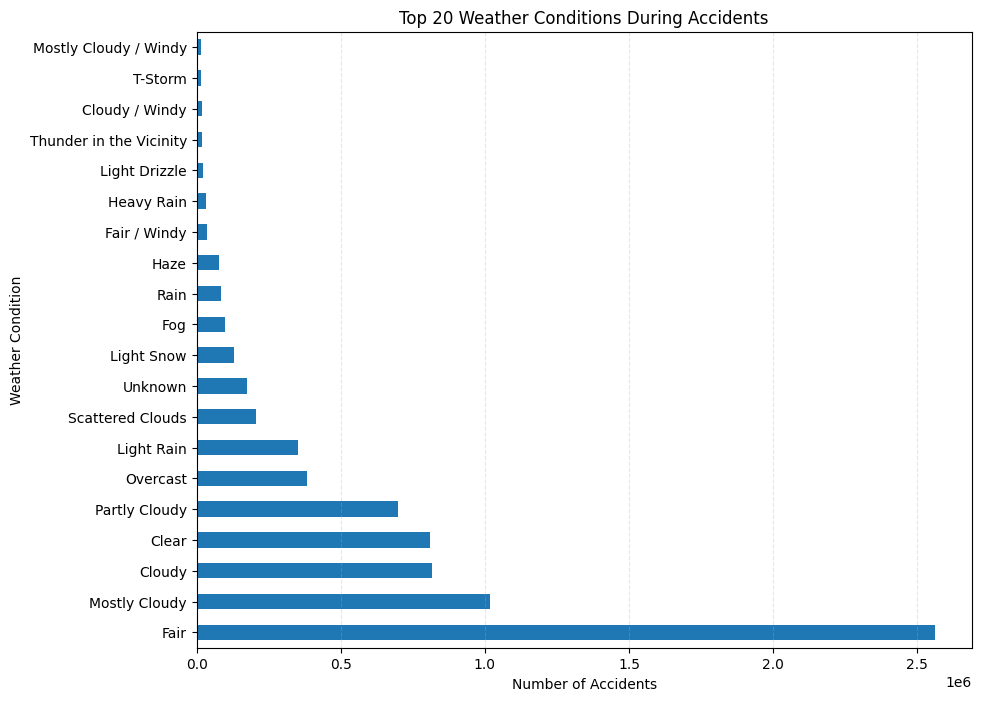

In [ ]:
top_weather=df['Weather_Condition'].value_counts().head(20)
top_weather.plot(kind="barh",figsize=(10, 8))

plt.title("Top 20 Weather Conditions During Accidents")
plt.xlabel("Number of Accidents")
plt.ylabel("Weather Condition")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.show()

In [58]:
top_humidity = df['Humidity_Group'].value_counts()
top_visibility = df['Visibility_Group'].value_counts()
top_wind_speed = df['Wind_Speed_Group'].value_counts()
top_precipitation = df['Precipitation_Group'].value_counts()

In [59]:
def fix_percentage_labels(ax, data, title):

    wedges, texts, autotexts = ax.pie(
        data,
        labels=None,
        autopct="%1.1f%%",
        startangle=90
    )

    # Get the percentage values
    percentages = (data / data.sum()) * 100

    # Find small percentage labels
    small = []

    for i, pct in enumerate(percentages):
        if pct < 5:
            small.append(i)

    # Move small percentage labels into a vertical sequence
    if len(small) > 1:

        # Sort them according to their original vertical position
        small = sorted(
            small,
            key=lambda i: autotexts[i].get_position()[1]
        )

        # Create evenly spaced Y positions
        y_positions = [
            0.55 + (i * 0.14)
            for i in range(len(small))
        ]

        for i, y in zip(small, y_positions):

            x = autotexts[i].get_position()[0]

            autotexts[i].set_position((x, y))

    ax.set_title(title)

    return wedges

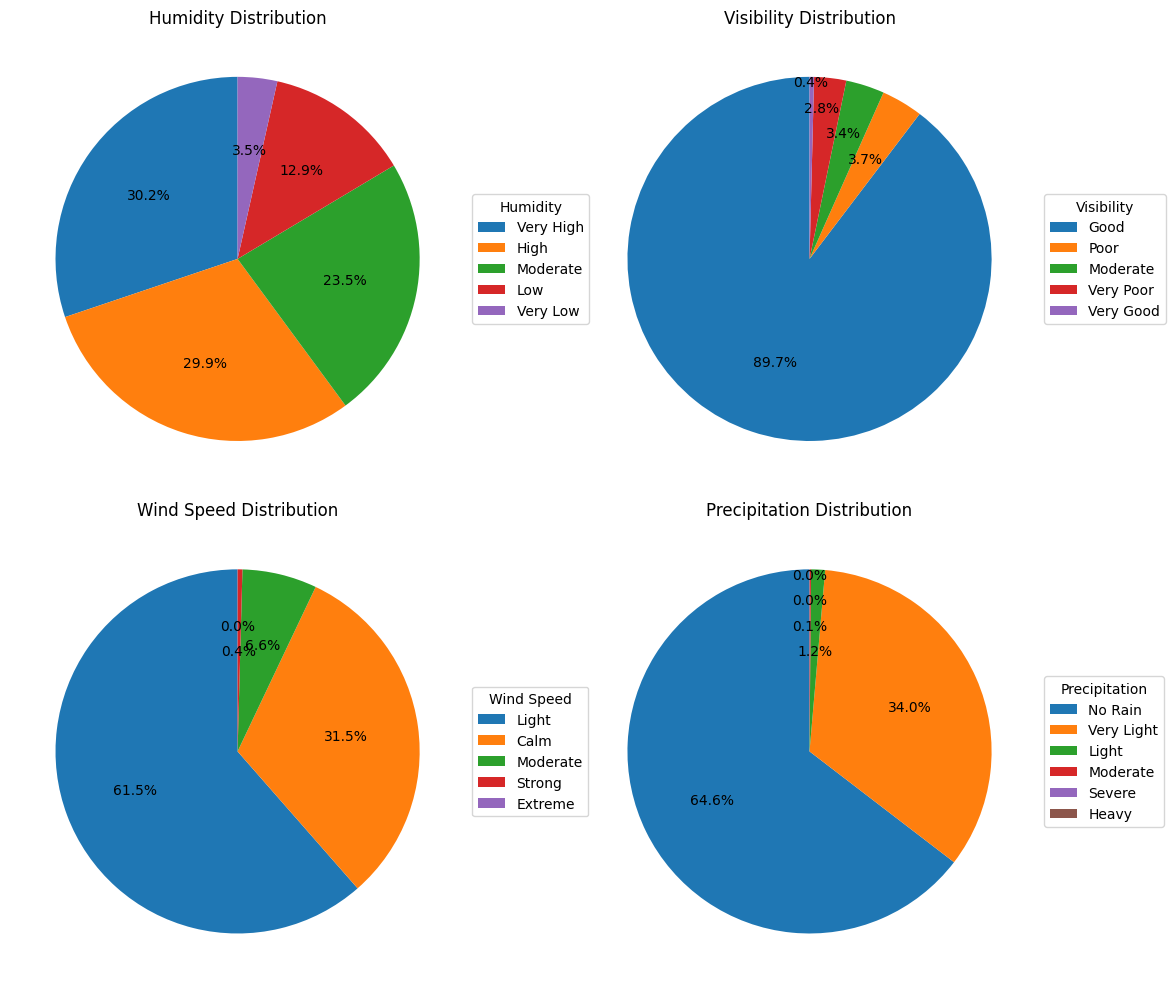

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))


# ---------------- HUMIDITY ----------------

wedges = fix_percentage_labels(
    axes[0, 0],
    top_humidity,
    "Humidity Distribution"
)

axes[0, 0].legend(
    wedges,
    top_humidity.index,
    title="Humidity",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)


# ---------------- VISIBILITY ----------------

wedges = fix_percentage_labels(
    axes[0, 1],
    top_visibility,
    "Visibility Distribution"
)

axes[0, 1].legend(
    wedges,
    top_visibility.index,
    title="Visibility",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)


# ---------------- WIND SPEED ----------------

wedges = fix_percentage_labels(
    axes[1, 0],
    top_wind_speed,
    "Wind Speed Distribution"
)

axes[1, 0].legend(
    wedges,
    top_wind_speed.index,
    title="Wind Speed",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)


# ---------------- PRECIPITATION ----------------

wedges = fix_percentage_labels(
    axes[1, 1],
    top_precipitation,
    "Precipitation Distribution"
)

axes[1, 1].legend(
    wedges,
    top_precipitation.index,
    title="Precipitation",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)


plt.tight_layout()
plt.show()

In [61]:
df["Sunrise_Sunset"].value_counts()

Sunrise_Sunset
Day        5334553
Night      2370595
Unknown      23246
Name: count, dtype: int64

In [62]:
print(f"Average Temperature across all the recorded accidents: {df['Temperature(C)'].mean().__round__(2)}")
print(f"Average Pressure across all the recorded accidents: {df['Pressure(in)'].mean().__round__(2)}")

### Average Temperature in Top States
avg_tem_top_states=df[df["State"].isin(top_states.index)].groupby("State")["Temperature(C)"].mean().round(2)

### Average Pressure in Top States
avg_pre_top_states=df[df["State"].isin(top_states.index)].groupby("State")["Pressure(in)"].mean().round(2)


### Average Wind speed in Top States
avg_wind_top_states=df[df["State"].isin(top_states.index)].groupby("State")["Wind_Speed(mph)"].mean().round(2)

top_states_weather=pd.concat([avg_tem_top_states,avg_pre_top_states,avg_wind_top_states],axis=1)

top_states_weather.columns = [
    "Average_Temperature(C)",
    "Average_Pressure(in)",
    "Average_Wind_Speed(mph)"
]

top_states_weather

Average Temperature across all the recorded accidents: 16.48
Average Pressure across all the recorded accidents: 29.54


,Average_Temperature(C),Average_Pressure(in),Average_Wind_Speed(mph)
State,,,
California,17.69,29.63,6.66
Florida,23.98,30.01,8.45
Minnesota,3.32,29.18,9.38
New York,12.71,29.81,8.93
North Carolina,17.13,29.60,6.78
Oregon,10.79,29.22,7.26
Pennsylvania,11.88,29.51,7.33
South Carolina,18.04,29.68,6.25
Texas,20.97,29.68,8.54


In [63]:
### Average Temperature in Top Cities
avg_tem_top_cities=df[df["City"].isin(top_20.index)].groupby("City")["Temperature(C)"].mean().round(2)

### Average Pressure in Top Cities
avg_pre_top_cities=df[df["City"].isin(top_20.index)].groupby("City")["Pressure(in)"].mean().round(2)


### Average Wind speed in Top Cities
avg_wind_top_cities=df[df["City"].isin(top_20.index)].groupby("City")["Wind_Speed(mph)"].mean().round(2)

top_cities_weather=pd.concat([avg_tem_top_cities,avg_pre_top_cities,avg_wind_top_cities],axis=1)
top_cities_weather.columns = [
    "Average_Temperature(C)",
    "Average_Pressure(in)",
    "Average_Wind_Speed(mph)"
]
top_cities_weather

,Average_Temperature(C),Average_Pressure(in),Average_Wind_Speed(mph)
City,,,
Atlanta,17.70,29.51,7.15
Austin,21.64,29.66,6.55
Baton Rouge,21.61,30.00,7.67
Charlotte,17.74,29.59,7.05
Columbia,18.94,29.91,5.87
Dallas,19.71,29.64,9.18
Houston,22.11,29.99,8.94
Jacksonville,21.52,30.03,8.52
Los Angeles,18.68,29.85,4.50


### Insights

1. **Weather conditions during accidents**

**Fair** is by far the most common recorded condition (about **2.5M+ accidents, roughly one-third of all records**), followed by Mostly Cloudy (~1.0M), Cloudy (~0.8M), Clear (~0.8M) and Partly Cloudy (~0.7M). Together, these five calm-sky conditions account for roughly **three-quarters** of all accidents. Adverse conditions are much smaller: Light Rain (~350K), Light Snow (~125K), Fog (~95K), while Rain, Haze, Heavy Rain and T-Storm each stay below ~100K. This mainly reflects **how often each condition occurs while people are driving**, so it should not be read as "fair weather is more dangerous".

2. **Humidity**

**60.1%** of accidents were recorded under High (29.9%) or Very High (30.2%) humidity, while Moderate accounts for 23.5%, Low for 12.9% and Very Low for only 3.5%. Humid conditions dominate the records, which matches the state-level findings in Section 4, although humidity alone cannot be treated as a cause.

3. **Visibility**

**89.7%** of accidents occurred under Good visibility. Poor (3.7%), Moderate (3.4%) and Very Poor (2.8%) visibility make up small shares, so only about **6.5%** of accidents happened under Poor or Very Poor visibility. Very Good visibility holds just **0.4%** of records; percentages for this group are based on a very small sample and should be read carefully (this matters again in Section 8).

4. **Wind speed**

Wind was rarely strong at the time of accidents: **93.0%** occurred under Light (61.5%) or Calm (31.5%) wind, 6.6% under Moderate wind, and only **0.4%** under Strong wind. Extreme wind is close to 0%. Wind speed therefore does not look like a common factor in the recorded accidents.

5. **Precipitation**

**64.6%** of accidents had No Rain and **34.0%** had Very Light precipitation, together **98.6%**. Light (1.2%) and Moderate (0.1%) precipitation are tiny shares, and Heavy/Severe round to 0.0%. As noted in Section 2, missing precipitation values were not filled, so these percentages describe only the records with a valid precipitation measurement.

6. **Day vs. Night**

**5.33M accidents (69.0%) happened during the day** and **2.37M (30.7%) at night**, with 23K records (0.3%) unknown. The higher daytime volume fits the earlier finding that accidents peak during the morning and afternoon commuting hours, because more vehicles are on the road. These counts alone do not show that daytime driving is riskier, since traffic volume is not part of the data.

7. **Temperature, Pressure and Wind in the Top 10 States**

The average temperature across all recorded accidents is **16.48 C** and the average pressure is **29.54 in**. Among the top 10 states, average temperature ranges from **3.32 C in Minnesota** to **23.98 C in Florida**, with California (17.69 C) close to the overall average. Accidents are therefore heavily recorded in both cold and warm climates, which suggests temperature alone does not explain where accidents concentrate. Average pressure stays within a narrow band (29.18-30.01 in), and average wind speed is light to moderate in every top state, from **6.25 mph in South Carolina** to **9.38 mph in Minnesota**.

8. **Temperature, Pressure and Wind in the Top 20 Cities**

City averages show a much wider temperature spread (about 21 C): **Miami (25.70 C), Orlando (24.23 C) and Phoenix (23.67 C)** are the warmest, while **Minneapolis (4.62 C)** is by far the coldest. Oklahoma City has the highest average wind speed (**12.03 mph**), followed by Minneapolis (9.69 mph) and Miami (9.24 mph), while Los Angeles has the lowest (4.50 mph). **Tucson (27.77 in) and Phoenix (29.00 in)** stand out with the lowest average pressure, which most likely reflects their higher elevation rather than unusual weather.

9. **Overall Weather Takeaway**

Most accidents were recorded in ordinary driving conditions: **Fair/cloudy skies, Good visibility, Calm-to-Light wind and no or very light precipitation**. Because these conditions are also what drivers face most of the time, accident counts by weather mainly show exposure rather than risk. Whether adverse weather changes the *seriousness* of accidents is examined in the Severity Analysis (Section 8).

## 6. Road Infrastructure Analysis

In [64]:
columns= ["Junction","Railway","Crossing","Stop","Traffic_Signal","Traffic_Calming","Give_Way","Roundabout","Bump"]

for col in columns:
    print(df[col].value_counts(),"\n")

Junction
False    7157052
True      571342
Name: count, dtype: int64 

Railway
False    7661415
True       66979
Name: count, dtype: int64 

Crossing
False    6854631
True      873763
Name: count, dtype: int64 

Stop
False    7514023
True      214371
Name: count, dtype: int64 

Traffic_Signal
False    6584622
True     1143772
Name: count, dtype: int64 

Traffic_Calming
False    7720796
True        7598
Name: count, dtype: int64 

Give_Way
False    7691812
True       36582
Name: count, dtype: int64 

Roundabout
False    7728145
True         249
Name: count, dtype: int64 

Bump
False    7724880
True        3514
Name: count, dtype: int64 



In [65]:
for col in columns:
        col_severity=pd.crosstab(
        df[col],
        df["Severity"]
        )
        print(col_severity,"\n")
    # col_severity=df.groupby([col,"Severity"]).size().unstack()
    # print(f"{col} X Severity")
    # print(col_severity)
    # print("\n")
    

Severity  Least Severe  Moderate  Most Severe  Serious
Junction                                              
False            64239   5741842       184130  1166841
True              3127    415139        20580   132496 

Severity  Least Severe  Moderate  Most Severe  Serious
Railway                                               
False            66302   6101200       203153  1290760
True              1064     55781         1557     8577 

Severity  Least Severe  Moderate  Most Severe  Serious
Crossing                                              
False            48675   5363435       191216  1251305
True             18691    793546        13494    48032 

Severity  Least Severe  Moderate  Most Severe  Serious
Stop                                                  
False            64723   5958591       199023  1291686
True              2643    198390         5687     7651 

Severity        Least Severe  Moderate  Most Severe  Serious
Traffic_Signal                                     

In [66]:
no_traffic_signal=df[df["Traffic_Signal"]==False]
no_traffic_signal["Distance(mi)"].mean()

np.float64(0.6414178933965404)

In [67]:
pd.crosstab(
    df["Junction"],
    df["Traffic_Signal"]
)

Traffic_Signal,False,True
Junction,,
False,6022608,1134444
True,562014,9328


In [68]:
pd.crosstab(
    df["Junction"],
    df["Traffic_Calming"]
)

Traffic_Calming,False,True
Junction,,
False,7149709,7343
True,571087,255


In [69]:
pd.crosstab(
    df["Junction"],
    df["Give_Way"]
)

Give_Way,False,True
Junction,,
False,7121886,35166
True,569926,1416


In [70]:
pd.crosstab(
    df["Railway"],
    df["Traffic_Signal"]
)

Traffic_Signal,False,True
Railway,,
False,6542258,1119157
True,42364,24615


In [71]:
pd.crosstab(
    df["Railway"],
    df["Traffic_Calming"]
)

Traffic_Calming,False,True
Railway,,
False,7653995,7420
True,66801,178


In [72]:
pd.crosstab(
    df["Railway"],
    df["Give_Way"]
)

Give_Way,False,True
Railway,,
False,7625307,36108
True,66505,474


In [73]:
pd.crosstab(
    df["Railway"],
    df["Stop"]
)

Stop,False,True
Railway,,
False,7449731,211684
True,64292,2687


In [74]:
pd.crosstab(
    df["Crossing"],
    df["Traffic_Signal"]
)

Traffic_Signal,False,True
Crossing,,
False,6254713,599918
True,329909,543854


In [75]:
pd.crosstab(
    df["Crossing"],
    df["Stop"]
)

Stop,False,True
Crossing,,
False,6711312,143319
True,802711,71052


In [76]:
pd.crosstab(
    df["Roundabout"],
    df["Give_Way"]
)

Give_Way,False,True
Roundabout,,
False,7691571,36574
True,241,8


In [77]:
pd.crosstab(
    df["Roundabout"],
    df["Traffic_Signal"]
)

Traffic_Signal,False,True
Roundabout,,
False,6584374,1143771
True,248,1


In [78]:
pd.crosstab(
    df["Roundabout"],
    df["Stop"]
)

Stop,False,True
Roundabout,,
False,7513806,214339
True,217,32


In [79]:
pd.crosstab(
    df["Bump"],
    df["Traffic_Calming"]
)

Traffic_Calming,False,True
Bump,,
False,7720796,4084
True,0,3514


### Insights

1. **How common is each infrastructure feature?**

Most recorded accidents are **not** flagged near any of these features. The most frequent are **Traffic Signal (1.14M, 14.8%)**, **Crossing (874K, 11.3%)** and **Junction (571K, 7.4%)**. Stop (214K, 2.8%), Railway (67K, 0.87%) and Give Way (37K, 0.47%) are less common, while **Traffic Calming (7.6K, 0.10%), Bump (3.5K, 0.05%) and Roundabout (only 249, 0.003%)** are very rare. A flag shows that a feature is near the accident location; it does not show that the feature caused the accident.

2. **Severity near each feature (Level 3 + Level 4 share)**

**Junction is the only major feature with a higher share of severe accidents**: Level 3 + 4 reaches **26.79%** near junctions compared with **18.88%** elsewhere (Level 3: 23.19% vs 16.30%, Level 4: 3.60% vs 2.57%). Every other major feature shows a lower severe share than the locations without it: **Crossing 7.04% vs 21.04%**, **Stop 6.22% vs 19.84%**, **Traffic Signal 9.51% vs 21.19%** and **Railway 15.13% vs 19.50%**. This is the same pattern seen in the top-city analysis in Section 5, now confirmed across the full dataset.

3. **Traffic signals and crossings**

Near traffic signals, Level 2 accidents make up **88.19%** of records (vs 78.19% elsewhere) and Level 3 falls to **7.75%** (vs 18.39%). Near crossings, Level 2 reaches **90.82%** and Level 3 only **5.50%** (vs 18.25%). The Level 1 share is also roughly **three to four times higher** near crossings (2.14% vs 0.71%) and signals (2.30% vs 0.62%). Since severity in this dataset describes traffic impact, a likely reason is that signals, crossings and stops sit mostly on slower urban roads where delays stay limited. This does not prove that these features reduce severity.

4. **Distance affected without traffic signals**

Accidents recorded without a traffic signal affect on average **0.64 miles** of road, higher than the dataset-wide average of **0.56 miles**. This suggests accidents away from signalised locations tend to disrupt a longer stretch of road, possibly because they happen more often on open, higher-speed roads, although speed is not available in the data.

5. **Junction and traffic-control flags rarely overlap**

Of the 571K junction accidents, only **9,328 (1.6%)** also carry a traffic signal flag, and only 1,416 carry a Give Way flag and 255 a Traffic Calming flag. In the other direction, **99.2%** of signal-flagged accidents are not flagged as junctions. This suggests that these flags mostly mark *different* locations in the data rather than overlapping ones, so a junction without a signal flag should not automatically be read as an unsignalised junction.

6. **Railway locations**

Railway accidents often coincide with other traffic controls: **36.8%** also have a traffic signal flag (vs 14.8% overall), 4.0% a Stop flag (vs 2.8%), 0.71% a Give Way flag (vs 0.47%) and 0.27% a Traffic Calming flag (vs 0.10%). This indicates railway crossings are frequently protected by additional controls. Railway accidents also show a lower severe share (15.13%) than non-railway accidents (19.50%), consistent with Section 5.

7. **Crossings and traffic control**

**62.2%** of crossing accidents have a traffic signal flag, compared with only **8.8%** of non-crossing accidents, and 8.1% have a Stop flag versus 2.1%. Conversely, **47.5% of all signal-flagged accidents** occur at crossings, so these two features largely describe the same busy, controlled urban locations.

8. **Roundabouts, Bumps and Traffic Calming**

Roundabouts have just **249** records (6 Level 4 and 5 Level 3, with no Level 1), and Bumps have 3,514 records. **Every bump accident (100%) is also flagged as Traffic Calming**, and bumps account for about 46% of all traffic calming records. Their severity percentages (for example 95.58% Level 2 for roundabouts) are based on too few records to draw reliable conclusions and should be treated as indicative only.

9. **Overall Infrastructure Takeaway**

Accidents near signals, crossings and stops are mostly lower-impact (Level 2) events, while **junction-related accidents carry the highest share of Level 3 and Level 4 incidents**, making junctions a priority for deeper investigation. These results describe patterns in *recorded* accidents only. The data has no traffic volume or total count of each feature, so it cannot say how risky one feature is compared with another.

## 7. Severity Analysis

In [80]:
df["Severity"].value_counts()

Severity
Moderate        6156981
Serious         1299337
Most Severe      204710
Least Severe      67366
Name: count, dtype: int64

In [95]:
severity_in_years=df.groupby(["Year","Severity"]).size().unstack(fill_value=0)
severity_in_years_rate=(severity_in_years.div(severity_in_years.sum(axis=1),axis=0)*100).round(2)
severity_in_years_rate

Severity,Least Severe,Moderate,Most Severe,Serious
Year,,,,
2016,0.05,65.73,3.49,30.72
2017,0.04,64.40,3.37,32.19
2018,0.03,64.32,2.89,32.76
2019,0.02,72.11,2.94,24.92
2020,2.41,79.24,2.64,15.72
2021,0.01,88.55,1.98,9.47
2022,2.15,90.97,2.46,4.42
2023,0.00,97.14,2.86,0.00


In [85]:
### checking how many records of 2023 are recorded in this dataset...

twe=df[df["Year"]==2023]
twe["Month"].unique()

array(['March', 'February', 'January'], dtype=object)

In [89]:
severity_in_states=df.groupby(["State","Severity"]).size().unstack(fill_value=0)
severity_in_states_rate=(severity_in_states.div(severity_in_states.sum(axis=1),axis=0)*100).round(2)
severity_in_states_rate


Severity,Least Severe,Moderate,Most Severe,Serious
State,,,,
Alabama,0.67,76.20,1.81,21.32
Arizona,4.33,82.38,3.00,10.29
Arkansas,0.16,84.46,12.41,2.97
California,0.59,83.03,0.78,15.61
Colorado,1.07,61.73,8.26,28.94
Connecticut,0.10,70.97,5.88,23.05
Delaware,1.66,82.26,11.01,5.07
District of Columbia,0.77,88.51,4.41,6.32
Florida,0.80,85.88,1.49,11.82


In [96]:
severity_by_hour=df.groupby(["Hour","Severity"]).size().unstack(fill_value=0)
severity_by_hour_rate=(severity_by_hour.div(severity_by_hour.sum(axis=1),axis=0)*100).round(2)
severity_by_hour_rate

Severity,Least Severe,Moderate,Most Severe,Serious
Hour,,,,
0,0.34,83.82,6.37,9.47
1,0.27,85.58,5.00,9.14
2,0.52,83.72,5.34,10.42
3,0.53,81.84,5.87,11.75
4,1.65,76.94,3.64,17.76
5,1.34,78.60,3.21,16.85
6,1.35,78.54,2.15,17.96
7,1.52,79.65,1.71,17.12
8,1.58,79.43,1.72,17.26


In [ ]:
### Severity analysis in top 20 weather conditons

severity_by_weather=df[df["Weather_Condition"].isin(top_weather.index)].groupby(["Weather_Condition","Severity"]).size().unstack(fill_value=0)
severity_by_weather_rate=(severity_by_weather.div(severity_by_weather.sum(axis=1),axis=0)*100).round(2)
severity_by_weather_rate

Severity,Least Severe,Moderate,Most Severe,Serious
Weather_Condition,,,,
Clear,0.04,66.40,3.27,30.29
Cloudy,0.98,84.81,2.79,11.42
Cloudy / Windy,0.61,84.49,2.67,12.23
Fair,1.34,86.95,2.33,9.38
Fair / Windy,1.00,86.47,2.84,9.68
Fog,0.67,86.87,2.80,9.66
Haze,0.29,79.51,1.41,18.79
Heavy Rain,0.60,74.69,2.33,22.38
Light Drizzle,0.65,75.12,3.31,20.92


In [104]:
severity_by_visibility=df.groupby(["Visibility_Group","Severity"],observed=False).size().unstack(fill_value=0)
severity_by_visibility_rate=(severity_by_visibility.div(severity_by_visibility.sum(axis=1),axis=0)*100).round(2)
severity_by_visibility_rate

Severity,Least Severe,Moderate,Most Severe,Serious
Visibility_Group,,,,
Very Poor,0.39,82.69,3.18,13.73
Poor,0.47,76.60,2.75,20.18
Moderate,0.50,78.39,2.57,18.54
Good,0.92,79.80,2.63,16.66
Very Good,0.68,67.67,3.53,28.11


In [105]:
severity_by_sunrise_set=df.groupby(["Sunrise_Sunset","Severity"],observed=False).size().unstack(fill_value=0)
severity_by_sunrise_set_rate=(severity_by_sunrise_set.div(severity_by_sunrise_set.sum(axis=1),axis=0)*100).round(2)
severity_by_sunrise_set_rate

Severity,Least Severe,Moderate,Most Severe,Serious
Sunrise_Sunset,,,,
Day,1.03,79.24,2.24,17.49
Night,0.52,80.56,3.50,15.42
Unknown,0.88,86.38,9.78,2.96


### Insights

*Note: the tables in this section label severity as Least Severe = Level 1, Moderate = Level 2, Serious = Level 3 and Most Severe = Level 4. Severity describes the impact on traffic flow, not injury or fatality (see Section 2.1).*

1. **Overall severity distribution**

**Moderate (Level 2)** accounts for 6.16M records (**79.7%**), followed by **Serious (Level 3)** with 1.30M (**16.8%**), **Most Severe (Level 4)** with 205K (**2.6%**) and **Least Severe (Level 1)** with 67K (**0.9%**). Levels 2 and 3 together make up **96.5%** of all accidents, so Level 4 events are relatively rare.

2. **Severity across years: a shift that needs caution**

The severity mix changes dramatically over time. Level 2 rises from **65.73% in 2016 to 90.97% in 2022 and 97.14% in 2023**, while Level 3 falls from **30.72% in 2016 (peaking at 32.76% in 2018) to 4.42% in 2022 and 0.00% in 2023**. Level 4 stays within a narrow 1.98-3.49% band, and Level 1 is near zero except in 2020 (2.41%) and 2022 (2.15%). Because accident counts grew strongly over the same period (Section 3), this near-total disappearance of Level 3 is unlikely to be a real safety improvement. It is more likely linked to **changes in how or from where severity was recorded over time**. Also, 2023 contains only January-March records. Year-wise severity trends should therefore be treated as a data characteristic, not a real-world improvement.

3. **Severity across states**

State differences are large. **South Dakota (20.76%), Wyoming (14.56%), Arkansas (12.41%), Delaware (11.01%) and Wisconsin (9.98%)** have the highest Level 4 shares, while **Minnesota (0.45%), North Dakota (0.49%), Oklahoma (0.58%), Rhode Island (0.70%) and California (0.78%)** have the lowest, a gap of more than 40 times between South Dakota and Minnesota. Level 3 is highest in **Rhode Island (45.54%), Kentucky (38.68%) and Georgia (36.19%)**, which also have the lowest Level 2 shares (52.65%, 56.60% and 55.67%). In contrast, **North Dakota (99.08%) and Montana (97.89%)** are almost entirely Level 2. Several of the highest Level 4 states have small accident volumes, and sharp differences between neighbouring states suggest that local reporting practices may influence these shares. The high-volume states (California, Florida, Texas) all have low Level 4 shares (0.78%, 1.49%, 1.24%), consistent with Section 4.

4. **Severity by hour of the day**

Accident volume and severity peak at different times. **Level 4 is highest late at night and in the early morning**: 6.37% at midnight, 5.00% at 1 am, 5.34% at 2 am, 5.87% at 3 am and still 5.26% at 11 pm. It is lowest during the commuting peaks (**1.71% at 7 am, 1.72% at 8 am, 1.99% at 5 pm**), so the Level 4 share at midnight is about **3.7 times** that at 7 am, even though these night hours have the fewest accidents. Level 3 is highest in the early evening (**18.77% at 6 pm and 18.47% at 7 pm**) and lowest overnight (9.14% at 1 am). Possible reasons for the night-time pattern, such as slower response or longer clearance, cannot be confirmed from this data.

5. **Severity across weather conditions**

- **Rain-related conditions show clearly higher Level 3 shares**: Heavy Rain (22.38%), Rain (21.62%), Light Drizzle (20.92%) and Light Rain (20.14%), compared with **Fair (9.38%)** and Cloudy (11.42%). Their combined Level 3 + 4 share (about **23-25%**) is roughly **double** that of Fair weather (11.71%), supporting the precipitation finding in Section 4.
- **Fog does not raise severity**: its Level 3 share (9.66%) is almost the same as Fair (9.38%). Light Snow has one of the highest Level 4 shares (3.70%), and Haze the lowest (1.41%).
- **A data artefact is likely in Scattered Clouds, Overcast and Clear**: these show the highest Level 3 (32.24%, 31.33%, 30.29%) and lowest Level 2 (about 65-66%) shares, even though they are calm conditions. They also have almost no Level 1 records (0.03-0.04%), which is the same signature as 2016-2018 in point 2 (Level 1 at 0.03-0.05%, Level 3 at 30-33%). This suggests these labels come mostly from the earlier period and its severity recording, not from a real weather effect. Clear skies should **not** be read as more dangerous.

6. **Severity across visibility groups**

There is **no consistent rise in severity as visibility gets worse**. Very Poor visibility has the highest Level 2 share (**82.69%**) and the lowest combined Level 3 + 4 share (**16.91%**), while Poor (22.93%), Moderate (21.11%) and Good (19.29%) are higher. Level 4 is slightly higher under Very Poor visibility (3.18%) than under Poor to Good (2.57-2.75%), but the gap is small. **Very Good visibility has the highest severe share (31.64%)**, but it covers only 0.4% of records and probably reflects the same early-period pattern as in point 5. This agrees with the findings in Sections 4 and 5 that poor visibility does not by itself lead to more severe accidents.

7. **Severity: day vs. night**

Night-time accidents are less frequent (30.7% of records) but have a **higher Level 4 share (3.50% vs 2.24% in daytime, about 1.6 times)**. Daytime has more Level 3 (17.49% vs 15.42%), so the combined Level 3 + 4 share is almost the same (19.73% day vs 18.92% night). This matches the hourly pattern in point 4: fewer accidents at night, but a larger share of the most severe ones. The Unknown group (23K records, 0.3%) shows a Level 4 share of 9.78%, but it is too small and unclear to interpret.

8. **Overall Severity Takeaway**

Most accidents have a moderate traffic impact, and the most severe cases cluster at **night, in specific states, and in junction-related locations**. Wet weather roughly doubles the share of Level 3 accidents, while low visibility and fog do not. Because severity shares shift strongly across years and weather labels, **year- and weather-based severity comparisons should be interpreted with the data-recording caveat in mind**.

## 9. Overall Summary

This analysis explored **7.73 million U.S. traffic accident records (2016 to March 2023) covering 49 states, 13,679 cities and 1,871 counties**. In this dataset, severity measures the **impact on traffic flow** (Level 1 = lowest, Level 4 = highest), not injury or fatality. The main findings are:

1. **When accidents happen**

Recorded accidents increased steadily from 2016 to 2022, and the first quarter of 2023 already ran at more than 80,000 per month, so the lower 2023 total reflects missing months, not a decline. **84.1% of accidents occurred on weekdays**, with peaks at **7 am, 8 am and 4 pm** (commuting hours), on **Wednesday to Friday**, and in **November, December and January**.

2. **Where accidents happen**

Accidents concentrate in a few states and large metropolitan areas: **California (1.7M+), Florida (~880K) and Texas (~580K)** lead the states, and **Miami (~190K), Houston, Los Angeles, Charlotte, Dallas and Orlando** lead the cities, each above 100,000. Hotspots follow major road networks and dense urban corridors. **A high accident volume does not mean a high share of severe accidents**: California, Florida and Texas all have low Level 4 shares (0.78%, 1.49%, 1.24%).

3. **Weather and environment**

Most accidents occurred in ordinary conditions: Fair or cloudy skies, **89.7% Good visibility, 93% Calm or Light wind and 98.6% no or very light precipitation**. These counts mainly reflect how often such conditions occur, not higher risk. Weather matters more for severity: **rain-related conditions roughly double the share of Level 3 accidents** compared with Fair weather, while fog and poor visibility do not raise it.

4. **Road infrastructure**

Traffic signals (14.8%), crossings (11.3%) and junctions (7.4%) are the most common flagged features, while most accidents have none. Accidents near **signals, crossings, stops and railways are mostly lower-impact**, whereas **junction accidents show the highest severe share (26.79% vs 18.88%)**. Roundabouts, bumps and traffic calming are too rare for reliable conclusions.

5. **Severity patterns**

**Level 2 dominates (79.7%)**, followed by Level 3 (16.8%), Level 4 (2.6%) and Level 1 (0.9%). The share of Level 4 is highest **late at night (about 5-6% from 11 pm to 3 am)** and lowest during the commuting peaks (about 1.7-2.0%), so volume and severity peak at different times. Night-time accidents are less frequent but have a higher Level 4 share than daytime (3.50% vs 2.24%), and large differences appear between states.

6. **Data limitations to keep in mind**

- **Severity shifts across years**: Level 3 falls from about 31% (2016) to 0% (2023) while Level 2 rises to 97%, which is more likely a change in severity recording than a real safety improvement.
- **Missing and extreme values**: many precipitation values were missing (and left unfilled), and extreme durations distort averages, for example Baton Rouge (mean 4,230 min vs median 59.85 min) and Oregon (912 min average).
- **Small groups**: rare categories such as Very Good visibility, roundabouts, bumps and low-volume states can show extreme percentages from few records.
- **No exposure data**: without traffic volume, population or road-length data, the results describe patterns in *recorded accidents*, not the risk per driver or per road. All relationships are associations, not proven causes.

7. **Possible next steps**

Normalising accident counts by population or traffic volume, investigating junction-related and night-time accidents in more depth, analysing wet-weather accidents by year to separate real effects from recording changes, and building a predictive severity model are natural extensions of this work.